In [3]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax


In [4]:
def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

## 2. Symmetric weight



In [5]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 3. Random initialisations and Adam optimisation to hit output targets

- draw many initial `theta`
- minimise a squared-error loss on target firing rates
- keep converged solutions

In [6]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 12  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 12
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=1.85, n_b=0.642, n_g=1.868, n_y=1.562


In [7]:
# define loss function
def loss_fn(theta):
    """Loss function: sum of squared differences from target firing rates"""
    r, g, b, y = mitral_output(theta, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
    loss = (jnp.sum((r - r_target) ** 2) +
            jnp.sum((g - g_target) ** 2) +
            jnp.sum((b - b_target) ** 2) +
            jnp.sum((y - y_target) ** 2))
    return loss

In [8]:
def adam_optimiser(
    loss_fn,
    theta_init,
    lr=0.03,
    steps=800,#1200,
    beta1=0.9,
    beta2=0.99,
    eps=1e-6,
    max_grad_norm=3.0,
    loss_tol=0,
    use_lr_schedule=True,
    log_every=20,
):
    
    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    if use_lr_schedule:
        learning_rate = optax.piecewise_constant_schedule(
            init_value=lr,
            boundaries_and_scales={400: 0.1, 800: 0.1},
        )
    else:
        learning_rate = lr

    optimizer = optax.chain(
        optax.clip_by_global_norm(max_grad_norm),
        optax.adam(learning_rate=learning_rate, b1=beta1, b2=beta2, eps=eps),
    )
    opt_state = optimizer.init(theta_init)

    loss_history = []
    theta = theta_init
    alpha_start_idx = 9
    alpha_end_idx = 10

    for step in range(steps):
        grad = grad_fn(theta)
        updates, opt_state = optimizer.update(grad, opt_state, theta)
        theta = optax.apply_updates(theta, updates)

        theta = jnp.clip(theta, 0.0, None)
        theta = theta.at[alpha_start_idx:alpha_end_idx].set(
            jnp.clip(theta[alpha_start_idx:alpha_end_idx], 0.0, 1.0)
        )

        loss_float = float(loss_fn_jit(theta))
        if step % log_every == 0 or step == steps - 1:
            loss_history.append(loss_float)
        if loss_float < loss_tol:
            if step % log_every != 0 and step != steps - 1:
                loss_history.append(loss_float)
            break

    return theta, loss_history

In [ ]:
# sample initial parameters
no_samples = 10  # number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=1.0)

print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 1000 initial parameter sets
Initial parameter matrix shape: (1000, 12)


In [10]:
# run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
r_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
y_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_unpacked = unpack_theta(theta_matrix[i, :], m)
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init  
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    r, g, b, y = mitral_output(theta_optimised, x, m, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)

    r_opt = r_opt.at[i, :].set(r)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    y_opt = y_opt.at[i, :].set(y)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()



Running Adam optimizer...

Sample 1/1000:


  Initial loss: 1.657293
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 2/1000:
  Initial loss: 1.819693
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 3/1000:
  Initial loss: 1.714748
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 4/1000:
  Initial loss: 1.429580
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 5/1000:
  Initial loss: 1.153486
  Final loss: 0.500000
  Output y: [0. 0.]

Sample 6/1000:
  Initial loss: 1.692775
  Final loss: 1.000000
  Output y: [0. 0.]

Sample 7/1000:
  Initial loss: 1.181859
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 8/1000:
  Initial loss: 1.076362
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 9/1000:
  Initial loss: 1.329485
  Final loss: 0.000000
  Output y: [0.50000006 0.50000006]

Sample 10/1000:
  Initial loss: 0.719477
  Final loss: 0.500000
  Output y: [0.5 0.5]

Sample 11/1000:
  Initial loss: 1.214273
  Final loss: 0.000000
  Output y: [0.5 0.5]

Sample 12/1000:
  Initial loss: 1.634792
  Final loss: 0.500000
 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


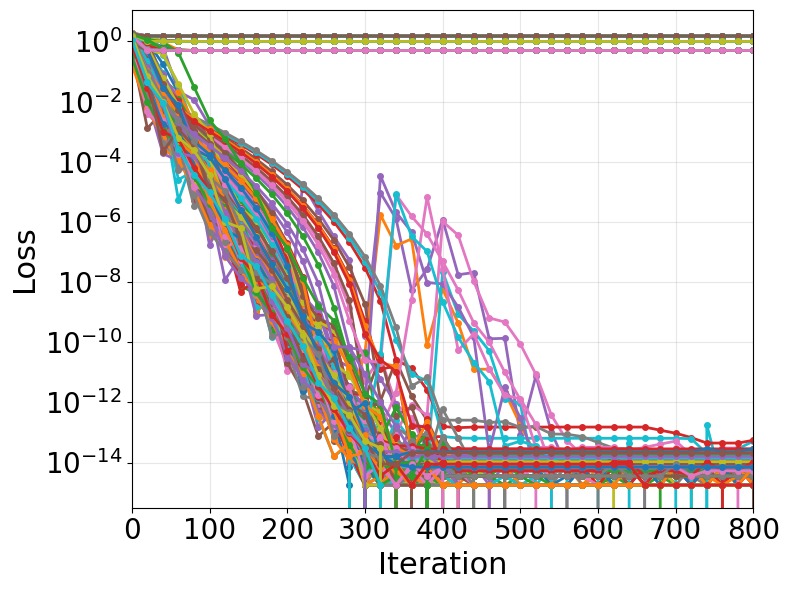

Optimisation results:
Target output: [0.5 0.5]

Optimised outputs:
  Sample 1: y = [0. 0.]
  Sample 2: y = [0. 0.]
  Sample 3: y = [0. 0.]
  Sample 4: y = [0. 0.]
  Sample 5: y = [0. 0.]
  Sample 6: y = [0. 0.]
  Sample 7: y = [0.5 0.5]
  Sample 8: y = [0.5 0.5]
  Sample 9: y = [0.50000006 0.50000006]
  Sample 10: y = [0.5 0.5]
  Sample 11: y = [0.5 0.5]
  Sample 12: y = [0. 0.]
  Sample 13: y = [0.5 0.5]
  Sample 14: y = [0. 0.]
  Sample 15: y = [0. 0.]
  Sample 16: y = [0.5 0.5]
  Sample 17: y = [0.5 0.5]
  Sample 18: y = [0.5 0.5]
  Sample 19: y = [0.5 0.5]
  Sample 20: y = [0.49999997 0.49999997]
  Sample 21: y = [0.50000006 0.50000006]
  Sample 22: y = [0.5 0.5]
  Sample 23: y = [0.50000006 0.50000006]
  Sample 24: y = [0.49999997 0.49999997]
  Sample 25: y = [0.5 0.5]
  Sample 26: y = [0.5 0.5]
  Sample 27: y = [0.5 0.5]
  Sample 28: y = [0. 0.]
  Sample 29: y = [0.5 0.5]
  Sample 30: y = [0. 0.]
  Sample 31: y = [0.5 0.5]
  Sample 32: y = [0.5 0.5]
  Sample 33: y = [0.5 0.5]
  S

In [16]:
plt.figure(figsize=(8, 6))

lines = []
for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    line, = plt.plot(steps, loss_hist, 'o-', linewidth=2, markersize=4)
    lines.append(line)  

plt.xlabel('Iteration', fontsize=22)
plt.ylabel('Loss', fontsize=22)
plt.yscale('log')
#plt.xlim(0, 500)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.xlim(0, 800)                   
plt.tight_layout()
plt.savefig('Figures_final/loss_convergence.eps')
plt.show()

print("Optimisation results:")
print(f"Target output: {np.array(y_target)}")
print(f"\nOptimised outputs:")
for i in range(y_opt.shape[0]):
    print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


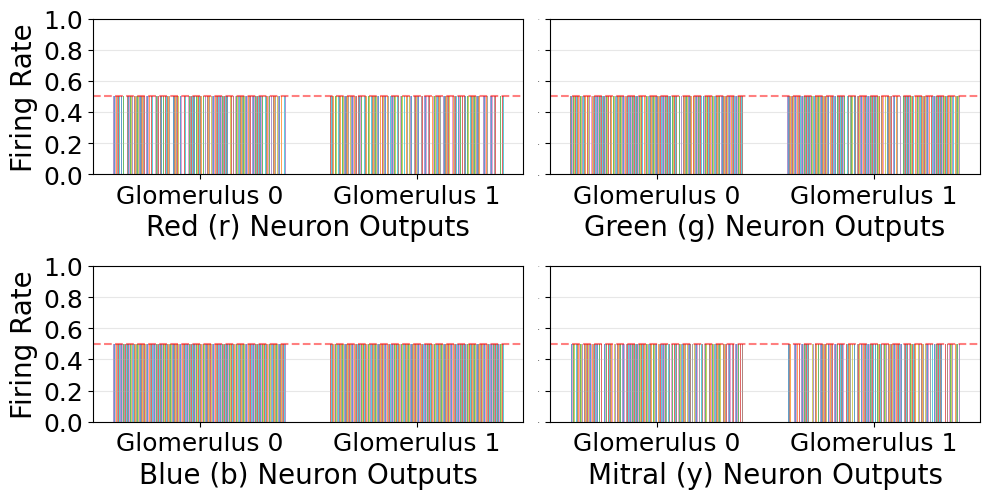

In [ ]:
# plot the output values of r, g, b, y for all samples
plt.figure(figsize=(8, 6))

# create subplots for each neuron type
neuron_types = ['Red (r)', 'Green (g)', 'Blue (b)', 'Mitral (y)']
outputs = [r_opt, g_opt, b_opt, y_opt]

for idx, (neuron_type, output) in enumerate(zip(neuron_types, outputs)):
    plt.subplot(2, 2, idx + 1)

    x_pos = np.arange(m)
    width = 0.8 / y_opt.shape[0]

    for i in range(y_opt.shape[0]):
        plt.bar(x_pos + i*width, np.array(output[i]), width,
                label=f'Sample {i+1}' if idx == 0 else '', alpha=0.7)

    plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5,
                alpha=0.5, label='Target (0.5)')

    if idx == 0 or idx == 2 :
        plt.ylabel('Firing Rate', fontsize=20)
        plt.yticks(fontsize=18)
    else:
        plt.yticks(fontsize=0)

    # subplot x-axis ticks
    plt.xticks(x_pos + 500*width, [f'Glomerulus {j}' for j in range(m)], fontsize=14)
    plt.xlabel(f'{neuron_type} Neuron Outputs', fontsize=20)
    plt.xticks(fontsize=18)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.savefig('Figures_final/neuron_outputs_rgby.eps')
plt.show()




In [13]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

# save theta_opt as pickle file
with open(f'Theta_opt/theta_opt_{theta_opt.shape[0]}_final.pkl', 'wb') as f:
    pickle.dump(theta_opt, f)

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 570 out of 1000
